# Longest summer dry spell vs. land warming, 30–60°N: CMIP6 multi-model (2021–2049)

Version of `cmip6_ens_land_dry_consect_temp_histo_fut.ipynb` with all CMIP6 models pooled: first member of each model (lowest r, then i, p, f).

- **Lines:** one KDE line per year (2021–2049). Each line is the distribution over the land cells of all models together in that year. Each model has the same total weight (its cos(lat) weights are scaled to sum to 1/n_models), so high-resolution models with more grid cells do not dominate. Lines are coloured by the multi-model mean land temperature change at 30–60°N relative to 2021 (mean over the models of each model's change).
- **Data:** the ssp370 ensemble files in `30-60N/ensemble` and annual `tas` from cmip6-ng. Land is `sftlf > 0`, with cos(lat) area weights. BCC-CSM2-MR has no sftlf file and uses the `FALLBACK_MASK_MODEL` mask. Only years in which every model has dry-spell and temperature data are used.
- **KDE:** weighted Gaussian KDE with Scott's bandwidth, as in `sns.kdeplot(weights=..., bw_adjust=1)`, computed directly (see `kde_curve`).
- **Regression (multi-model mean):** x is the multi-model mean raw annual land temperature, y is the multi-model mean of each model's area-weighted land-mean longest dry spell, one point per year. Averaging over models removes much of the year-to-year noise, so R² is usually higher than for single models. The per-model regressions are also saved for comparison; their mean slope is not the same as the multi-model-mean slope.

In [1]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')

In [2]:
# ── settings ─────────────────────────────────────────────────────────────────
ENS_DIR       = '/home/jwille/xenon_data/NextGEMS/dry_spells/CMIP6/30-60N/ensemble'   # dry_spell_<model>_ssp370_ensemble_native.nc
TAS_DIR       = '/net/atmos/data/cmip6-ng/tas/ann/native'
SFTLF_DIR     = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT    = 'ssp370'
YEARS         = (2021, 2049)
REF_YEAR      = 2021
latitude      = [30, 60]

FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask used for models without an sftlf file (BCC-CSM2-MR)
EXCLUDE_MODELS      = []                # e.g. ['BCC-CSM2-MR']

CBAR_RANGE = (-0.1, 2.4)                # colour-bar limits (°C); None = range of the data
LINE_WIDTH = 2.0                        # one line per year (as in the CESM2 original)

# KDE evaluation grid and plot range (as in the original)
xmin, xmax = 0, 185
bin_width  = 2
X_GRID     = np.linspace(xmin, xmax, 371)

OUT_FIG   = '/home/jwille/images/global_paper/mid_lat_land_cmip6_mmm_histo_dry_spell_temp.pdf'
OUT_TABLE = '/home/jwille/images/global_paper/mid_lat_land_cmip6_mmm_dry_spell_temp_regression.csv'


In [3]:
FNAME = re.compile(r'^(?P<prefix>dry_spell|tas_ann)_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mask(model, lat, lon):
    path = find_sftlf(model)
    src = xr.open_dataset(path or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    return (nearest_regrid(src, lat, lon) > 0).values, (os.path.basename(path) if path else f'{FALLBACK_MASK_MODEL} (fallback)')


def kde_curve(values, weights, x_grid):
    """Weighted Gaussian KDE with Scott's bandwidth, identical to sns.kdeplot(x=values, weights=weights,
    bw_adjust=1) (density). Values are aggregated to distinct lengths with summed weights; the bandwidth
    and weighted covariance are those of the full sample."""
    w = weights / weights.sum()
    u, inv = np.unique(values, return_inverse=True)
    agg = np.bincount(inv, weights=w)
    sw2 = np.sum(w ** 2)
    if u.size < 2:
        return np.zeros_like(x_grid)
    bw = sw2 ** (1 / 5) * np.sqrt((1 - np.sum(agg ** 2)) / (1 - sw2))
    return stats.gaussian_kde(u, weights=agg, bw_method=bw)(x_grid)

In [4]:
# ── first member of every model: land values and weights per year, land-mean dry spell and temperature ──
ENS = re.compile(r'^dry_spell_(?P<model>[^_]+)_(?P<exp>[^_]+)_ensemble_[^_]+\.nc$')
ens_files = sorted(((m['model'], f) for f in os.listdir(ENS_DIR)
                    if (m := ENS.match(f)) and m['exp'] == EXPERIMENT and m['model'] not in EXCLUDE_MODELS),
                   key=lambda mf: mf[0].lower())
tas_files = {(m['model'], m['member']): f for f in os.listdir(TAS_DIR)
             if (m := FNAME.match(f)) and m['prefix'] == 'tas_ann' and m['exp'] == EXPERIMENT}


def member_labels(ds):
    """Member names of an ensemble file: 'member_labels' attribute (NCO version, member = 1..N)
    or the member coordinate itself (Python version, member = 'r1i1p1f1', ...)."""
    lab = ds['member'].attrs.get('member_labels') or ds.attrs.get('member_labels')
    return lab.split(',') if lab else [str(m) for m in ds['member'].values]


per_model = {}      # model -> member, values {year: (land values, cos(lat) weights)}, dry (Series), tas (Series)

for model, fname in ens_files:
    ens = xr.open_dataset(os.path.join(ENS_DIR, fname))
    labels = member_labels(ens)
    if len(labels) != ens.sizes['member']:
        raise ValueError(f'{model}: {len(labels)} member labels but {ens.sizes["member"]} members in {fname}')
    i = min(range(len(labels)), key=lambda k: member_sort_key(labels[k]))   # first member
    mem = labels[i]
    if (model, mem) not in tas_files:
        print(f'{model} {mem}: no tas file, model skipped')
        continue
    da = ens['dry_spell'].isel(member=i).sel(year=slice(*YEARS)).load()

    land, mask_name = land_mask(model, da.lat.values, da.lon.values)
    w_land = (np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon']))[land]

    # annual tas, land 30-60N area mean
    tas = xr.open_dataset(os.path.join(TAS_DIR, tas_files[(model, mem)]))['tas'].load()
    tas = tas.assign_coords(time=tas.time.dt.year).rename(time='year').sel(year=slice(*YEARS))
    tas = tas.isel(lat=np.where((tas.lat.values >= latitude[0]) & (tas.lat.values <= latitude[1]))[0])
    tland, _ = land_mask(model, tas.lat.values, tas.lon.values)
    tw = np.cos(np.deg2rad(tas.lat.values))[:, None] * np.ones(tas.sizes['lon'])
    tas_mean = pd.Series([np.average(tas.sel(year=y).values[tland], weights=tw[tland]) for y in tas.year.values],
                         index=tas.year.values.astype(int))

    values, dry = {}, {}
    for y in da.year.values:
        v = da.sel(year=y).values[land]
        ok = np.isfinite(v)
        values[int(y)] = (v[ok], w_land[ok])
        dry[int(y)] = np.average(v[ok], weights=w_land[ok])
    per_model[model] = dict(member=mem, values=values, dry=pd.Series(dry), tas=tas_mean)
    print(f'{model:14s} {mem}, {len(values)} years, mask: {mask_name}')

# years with dry spells and temperature in every model
years = sorted(set.intersection(*[set(d['dry'].index) & set(d['tas'].index) for d in per_model.values()]))
for model, d in per_model.items():
    missing = sorted(set(range(YEARS[0], YEARS[1] + 1)) - (set(d['dry'].index) & set(d['tas'].index)))
    if missing:
        print(f'{model}: missing years {missing}')
if REF_YEAR not in years:
    raise ValueError(f'reference year {REF_YEAR} is not available in every model')
n_models = len(per_model)
print(f'\n{n_models} models, {len(years)} years ({years[0]}-{years[-1]})')

# multi-model means per year
tas_df = pd.DataFrame({m: d['tas'] for m, d in per_model.items()}).loc[years]
dry_df = pd.DataFrame({m: d['dry'] for m, d in per_model.items()}).loc[years]
mmm_dT  = (tas_df - tas_df.loc[REF_YEAR]).mean(axis=1)    # mean over models of each model's warming since REF_YEAR
mmm_tas = tas_df.mean(axis=1)
mmm_dry = dry_df.mean(axis=1)

# one line per year: all models pooled, each model's weights scaled to sum to 1 / n_models
lines = []
for y in years:
    vals = np.concatenate([d['values'][y][0] for d in per_model.values()])
    wts  = np.concatenate([d['values'][y][1] / d['values'][y][1].sum() / n_models for d in per_model.values()])
    lines.append(dict(year=y, dT=float(mmm_dT.loc[y]), curve=kde_curve(vals, wts, X_GRID)))
print(mmm_dT.round(2).to_string())


ACCESS-ESM1-5  r1i1p1f1, 29 years, mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 29 years, mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, 29 years, mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, 29 years, mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
CESM2          r1i1p1f1, 29 years, mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 29 years, mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, 29 years, mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 29 years, mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, 29 years, mask: sftlf_fx_GFDL-ESM4_historical_r1i1p1f1_native.nc
INM-CM5-0      r1i1p1f1, 29 years, mask: sftlf_fx_INM-CM5-0_historical_r1i1p1f1_native.nc
IPSL-CM6A-LR   r1i1p1f1, 29 years, mask: sftlf_fx_IPSL-CM6A-LR_historical_r1i1p1f1_native.nc
MIROC6         r1i1p1f1, 29 year

In [5]:
# ── regression: multi-model mean land dry spell vs multi-model mean raw annual land temperature ──
mmm_lin = stats.linregress(mmm_tas.values, mmm_dry.values)
print(f'CMIP6 multi-model mean: slope {mmm_lin.slope:.3f} days/°C, R² {mmm_lin.rvalue ** 2:.3f}, p {mmm_lin.pvalue:.2e}')

# per-model regressions (first member, raw annual temperature), for comparison
rows = []
for model in per_model:
    r = stats.linregress(tas_df[model].values, dry_df[model].values)
    rows.append(dict(model=model, member=per_model[model]['member'], years=len(years),
                     slope=r.slope, r_squared=r.rvalue ** 2, p_value=r.pvalue))
regression = pd.DataFrame(rows).set_index('model')
regression.loc['mean of models', ['slope', 'r_squared', 'p_value']] = regression[['slope', 'r_squared', 'p_value']].mean()
regression.loc['multi-model mean', ['years', 'slope', 'r_squared', 'p_value']] = [len(years), mmm_lin.slope,
                                                                                mmm_lin.rvalue ** 2, mmm_lin.pvalue]
os.makedirs(os.path.dirname(OUT_TABLE), exist_ok=True)
regression.to_csv(OUT_TABLE)
regression.style.format({'slope': '{:.3f}', 'r_squared': '{:.3f}', 'p_value': '{:.2e}', 'years': '{:.0f}'}, na_rep='')


CMIP6 multi-model mean: slope 0.844 days/°C, R² 0.435, p 1.01e-04


,member,years,slope,r_squared,p_value
model,,,,,
ACCESS-ESM1-5,r1i1p1f1,29,-0.289,0.005,7.25e-01
BCC-CSM2-MR,r1i1p1f1,29,0.700,0.082,1.33e-01
CAMS-CSM1-0,r2i1p1f1,29,1.147,0.066,1.77e-01
CanESM5,r1i1p2f1,29,0.304,0.018,4.83e-01
CESM2,r1i1p1f1,29,0.770,0.042,2.87e-01
CNRM-ESM2-1,r1i1p1f2,29,0.633,0.035,3.33e-01
EC-Earth3,r1i1p1f1,29,0.420,0.007,6.73e-01
FGOALS-g3,r1i1p1f1,29,-0.485,0.023,4.36e-01
GFDL-ESM4,r1i1p1f1,29,2.135,0.188,1.87e-02


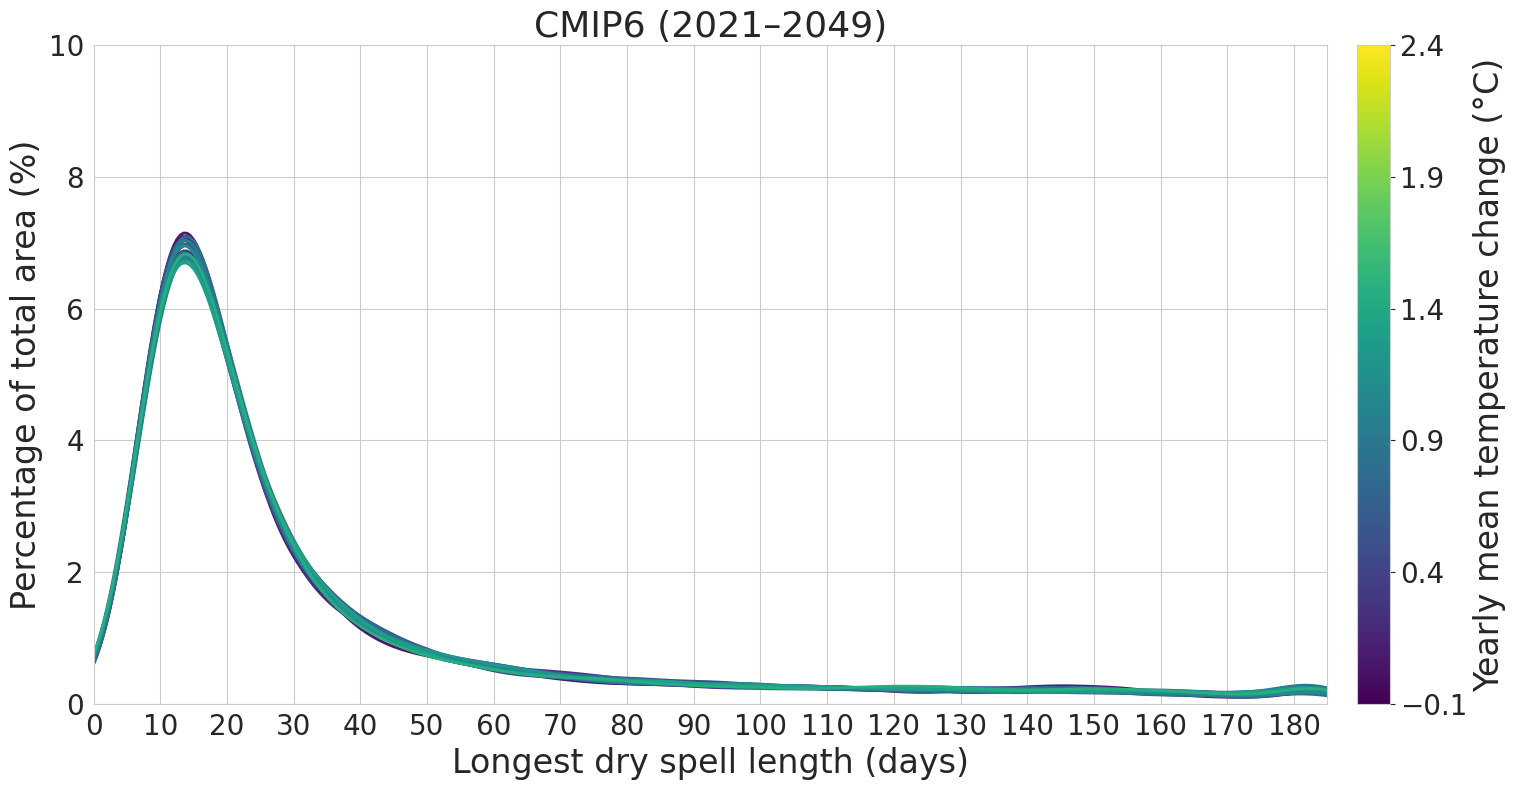

In [7]:
# ── plot: one line per year (all models pooled), coloured by the multi-model mean land warming since REF_YEAR ──
dT_all = np.array([l['dT'] for l in lines])
vmin, vmax = CBAR_RANGE if CBAR_RANGE is not None else (np.floor(dT_all.min() * 10) / 10, np.ceil(dT_all.max() * 10) / 10)
cmap = plt.get_cmap('viridis')
norm = plt.Normalize(vmin=vmin, vmax=vmax)

order = np.argsort(dT_all)                     # warmest lines drawn last (on top)
segments = [np.column_stack([X_GRID, lines[i]['curve'] * bin_width * 100]) for i in order]   # density -> % per bin

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")
ax.add_collection(LineCollection(segments, colors=cmap(norm(dT_all[order])), linewidths=LINE_WIDTH))

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=np.linspace(vmin, vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)

# beta1 = slope of the multi-model mean regression; R² in bold when p < 0.05
#r2 = mmm_lin.rvalue ** 2
#r2_txt = (r'$\mathbf{R^2 = %.2f}$' if mmm_lin.pvalue < 0.05 else r'$\mathrm{R^2 = %.2f}$') % r2
#ax.text(0.97, 0.95, rf"$\beta_1$ = {mmm_lin.slope:.2f} d/°C" + '\n' + r2_txt,
#        transform=ax.transAxes, ha='right', va='top', fontsize=20,
#        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))

ax.set_xticks(np.arange(xmin, xmax, 10))
ax.set_ylim(0, 10)
ax.set_xlim(xmin, xmax)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Percentage of total area (%)', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_title(f'CMIP6 ({years[0]}–{years[-1]})', fontsize=26)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()
